# Dimensionless-number analysis

Run the same four operating points used in `overpotential_breakdown.ipynb`:

- **Test 5** at SOC 10 %, **discharge**
- **Test 16** at SOC 50 %, **discharge**
- **Test 16** at SOC 50 %, **charge**
- **Test 25** at SOC 90 %, **charge**

Each case is run galvanostatically to steady state (or the SOC cut-off event). This
first part just runs and persists the converged cases, together with the cathode's
local **ionic conductivity** ($\kappa_{io}$) and **exchange current density**
($i_0$, from the Butler-Volmer equation) along the cathode thickness, so later
dimensionless-number cells in this notebook don't need to re-run the DAE solve.

**Workflow:** run all -> results are cached in `results/adim_analysis_cases.npz`.

In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import membraneparams, cathodeparams, anodeparams

## Parameters

Same four cases as `overpotential_breakdown.ipynb`, each forced to the same
$|j_{appl}| = 2000$ A/m² used there so the cases are directly comparable.

In [2]:
CASES = [
    {"test": 5,  "mode": "discharge", "label": "Test 5 - SOC 10% discharge"},
    {"test": 16, "mode": "discharge", "label": "Test 16 - SOC 50% discharge"},
    {"test": 16, "mode": "charge",    "label": "Test 16 - SOC 50% charge"},
    {"test": 25, "mode": "charge",    "label": "Test 25 - SOC 90% charge"},
]

I_APPL_ABS = 2000.0  # A/m^2 geometric electrode area, same override used in overpotential_breakdown.ipynb

TF   = 1800   # s, simulation horizon
RTOL = 1e-5

data_exp = pd.read_csv(ROOT / "data" / "experimental" / "HFR.csv")

## Run simulations

In [3]:
results = {}

for case in CASES:
    test_no, mode = case["test"], case["mode"]
    print(f"=== {case['label']} ===")

    d   = data_exp[data_exp["test_no"] == test_no]
    soc = d["SOC"].iloc[0]
    T   = d["T(°C)"].iloc[0]
    Q_v = d["Q_v (ml/min)"].iloc[0]

    i_appl = I_APPL_ABS if mode == "charge" else -I_APPL_ABS
    print(f"  SOC={soc}, T={T} degC, Q_v={Q_v} ml/min, i_appl={i_appl:+.1f} A/m2")

    # -- fitted parameters --------------------------------------------------
    fit_dir = ROOT / "results" / "test fitting" / f"test {test_no}"
    hfr_fit = sorted(fit_dir.glob(f"fit_v2_test{test_no}_*.json"))[-1]
    e_fit   = sorted(fit_dir.glob(f"fit_e_cell_test{test_no}_*.json"))[-1]

    with open(hfr_fit) as f:
        fit = json.load(f)
    p, s = fit["params"], fit["settings"]
    membraneparams.k_sorp_vw   = p["k_vw_sorp"]
    membraneparams.k_desorp_vw = p["S_desorp"] * p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = p["k_lw_sorp"]
    membraneparams.k_desorp_lw = p["S_desorp"] * p["k_lw_sorp"]
    membraneparams.k_ca_lw     = p["k_ca"]
    membraneparams.sf_D        = s["sf_D"]
    R_extra = [v for k, v in p.items() if k.startswith("R_extra")][0] / 1e4  # Ohm.cm2 -> Ohm.m2

    with open(e_fit) as f:
        e_params = json.load(f)["params"]
    cathodeparams.reaction_rate_constant = e_params["k_ca"]
    anodeparams.j_0                      = e_params["j0_an"]

    # -- run to steady state -------------------------------------------------
    cell, y0, yp0 = build_cell(soc, i_appl, T, Q_v)
    atol         = build_atol(cell)
    jac_sparsity = cell.compute_jac_sparsity(y0, yp0)

    t0  = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    print(f"  t_final={sol.t[-1]:.1f} s  ({time.time()-t0:.1f} s wall)")

    y_final, yp_final = sol.y[:, -1], sol.yp[:, -1]
    cell.dae_residual_full_cell(sol.t[-1], y_final, yp_final)  # refresh cell.eta_proton etc.

    results[test_no, mode] = dict(
        case=case, mode=mode, cell=cell, y=y_final, i_appl=i_appl,
        R_extra=R_extra, soc=soc, T=T, Q_v=Q_v,
    )

print(f"\nFinished {len(results)} case(s): {list(results.keys())}")

=== Test 5 - SOC 10% discharge ===
  SOC=0.1, T=32 degC, Q_v=45 ml/min, i_appl=-2000.0 A/m2
  t_final=1800.0 s  (7.2 s wall)
=== Test 16 - SOC 50% discharge ===
  SOC=0.5, T=32 degC, Q_v=45 ml/min, i_appl=-2000.0 A/m2
  t_final=1800.0 s  (4.6 s wall)
=== Test 16 - SOC 50% charge ===
  SOC=0.5, T=32 degC, Q_v=45 ml/min, i_appl=+2000.0 A/m2
  t_final=1800.0 s  (49.4 s wall)
=== Test 25 - SOC 90% charge ===
  SOC=0.9, T=32 degC, Q_v=45 ml/min, i_appl=+2000.0 A/m2
  t_final=1800.0 s  (40.1 s wall)

Finished 4 case(s): [(5, 'discharge'), (16, 'discharge'), (16, 'charge'), (25, 'charge')]


## Cathode ionic conductivity and exchange current density

For each case, extract along the cathode thickness:

- the local effective **ionic conductivity** $\kappa_{io}$ (S/m), plus its
  thickness-weighted **effective** (homogenised) value;
- the local Butler-Volmer **exchange current density**
  $i_0 = F\,k_{ca}\,c_{V(V)}^{\alpha_c}\,c_{V(IV)}^{1-\alpha_c}$ (A/m²), using the
  same regularised bulk concentrations as `cell.butler_volmer`.

In [4]:
cases_data = {}

for (test_no, mode), r in results.items():
    cell, y, i_appl = r["cell"], r["y"], r["i_appl"]
    state = cell.split_state(y)
    cath  = state["cathode"]
    c_V4_ca, c_V5_ca, c_H_ca = cath[:, 0], cath[:, 1], cath[:, 2]
    dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness        # node widths [m]
    x_um  = (np.cumsum(dx_ca) - dx_ca / 2) * 1e6                      # node centres [um]
    l_ca  = cell.cathode.thickness                                   # cathode thickness [m]
    # -- ionic conductivity along the cathode thickness ----------------------
    kappa_io     = cell.cathode.kappa_io                              # local, S/m
    kappa_io_eff = np.sum(kappa_io * dx_ca) / np.sum(dx_ca)  # effective, S/m
    # -- exchange current density j_0_ca [A/m2 active surface], same formula/regularisation as BV
    eps     = 1e-4
    c_V4b   = np.sqrt(np.maximum(c_V4_ca, 0)**2 + eps**2)
    c_V5b   = np.sqrt(np.maximum(c_V5_ca, 0)**2 + eps**2)
    alpha_c = cell.alpha_c
    k_ca    = cell.cathode.reaction_rate_constant
    F       = cell.F
    j_0_ca  = F * k_ca * (c_V5b**alpha_c) * (c_V4b**(1 - alpha_c))    # local, A/m2 active surface
    a       = cell.cathode.specific_surface_area                   # m2_active/m3_electrode
    # Damkoler pore level
    Re      = cell.cathode.rho_ca * cell.cathode.u_ip * cell.d_f / cell.cathode.mu_ca
    Sh      = 7*Re**0.4
    if i_appl > 0: # Charge
        Da_pore = np.abs(i_appl) * cell.d_f / (a * F * l_ca * Sh * (1.03 * 1000 *(1 - r["soc"])) * cell.D_V4)  # Pavan 2020
    else: # Discharge
        Da_pore = np.abs(i_appl) * cell.d_f / (a * F * l_ca * Sh * (1.03 * 1000 * (r["soc"])) * cell.D_V5)
    # Damkoler salt
    if i_appl > 0: # Charge
        Da_salt = np.abs(i_appl) * l_ca / (F * (1.03 * 1000 *(1 - r["soc"])) * cell.D_V5)  # Pavan 2020
    else:
        Da_salt = np.abs(i_appl) * l_ca / (F * (1.03 * 1000 * (r["soc"])) * cell.D_V4)

    # cathode overpotential and beta_0
    eta     = cell.cathode.eta
    k_m     = 7 * cell.cathode.D_V4_eff / cell.d_f * (cell.d_f / (cell.cathode.mu_ca / cell.cathode.rho_ca))**(0.4)
    beta_0  = k_m * cell.cathode.u_ip**0.4                         # Mass transfer coefficient
    if i_appl > 0: # Charge
        i_lim = F * beta_0 * (1.03 * 1000 *(1 - r["soc"]))
    else: # Discharge
        i_lim = F * beta_0 * (1.03 * 1000 * (r["soc"]))

    cases_data[test_no, mode] = dict(
        label=r["case"]["label"], i_appl=i_appl, soc=r["soc"], T=r["T"], Q_v=r["Q_v"],
        x_um=x_um, dx_ca=dx_ca,
        c_V4=c_V4_ca, c_V5=c_V5_ca, c_H=c_H_ca,
        kappa_io=kappa_io,
        j_0_ca=j_0_ca, k_ca=k_ca, alpha_c=alpha_c,
    )

    print(f"{r['case']['label']:28s} "
          f"j_0_ca: min={j_0_ca.min():.4e}  max={j_0_ca.max():.4e} A/m2 active, "
          f"kappa_io_eff: {kappa_io_eff:.4e} S/m, "
          f"i_lim: {i_lim:.4e} A/m2, "
          f"Da_pore: {Da_pore:.4e} [-], "
          f"Da_salt: {Da_salt:.4e} [-]")

Test 5 - SOC 10% discharge   j_0_ca: min=8.1505e+00  max=1.6216e+01 A/m2 active, kappa_io_eff: 1.8226e+02 S/m, i_lim: 3.0090e+02 A/m2, Da_pore: 9.1450e-03 [-], Da_salt: 2.3737e+03 [-]
Test 16 - SOC 50% discharge  j_0_ca: min=4.6847e+01  max=5.2394e+01 A/m2 active, kappa_io_eff: 1.7831e+02 S/m, i_lim: 1.5045e+03 A/m2, Da_pore: 1.8290e-03 [-], Da_salt: 4.7474e+02 [-]
Test 16 - SOC 50% charge     j_0_ca: min=5.0585e+01  max=5.4968e+01 A/m2 active, kappa_io_eff: 1.7932e+02 S/m, i_lim: 1.5045e+03 A/m2, Da_pore: 1.8290e-03 [-], Da_salt: 4.7474e+02 [-]
Test 25 - SOC 90% charge     j_0_ca: min=1.2689e+01  max=2.2367e+01 A/m2 active, kappa_io_eff: 1.7538e+02 S/m, i_lim: 3.0090e+02 A/m2, Da_pore: 9.1450e-03 [-], Da_salt: 2.3737e+03 [-]


## Second Damköhler number — pore-level film diffusion vs. reaction (Da$_{II}$)

Two characteristic molar fluxes at the **pore surface** [mol m$^{-2}_\text{pore}$ s$^{-1}$] are compared:

$$R_{\text{reac,pore}} = \frac{i_\text{appl}}{n F \, a \, l_{ca}}$$

reaction flux per unit pore area, distributing the applied current over the total pore
surface area $a \, l_{ca}$ [m$^2_\text{pore}$ m$^{-2}_\text{geo}$].

$$R_{\text{diff,film}} = \beta_0 \, c_\text{bulk}$$

pore-film diffusion flux, where $\beta_0$ [m/s] is the mass-transfer coefficient and
$c_\text{bulk}$ [mol m$^{-3}$] is the bulk vanadium concentration.

$$\text{Da}_{II} = \frac{R_{\text{reac,pore}}}{R_{\text{diff,film}}} = \frac{i_\text{appl}}{n F \, a \, l_{ca} \, \beta_0 \, c_\text{bulk}}$$

$\text{Da}_{II} \gg 1$: reaction demand exceeds diffusion supply -> mass-transfer limited.  
$\text{Da}_{II} \ll 1$: diffusion supply is fast relative to reaction -> reaction-limited.

In [5]:
n = 1  # electrons per vanadium redox event

print(f"{'Case':28s}  {'β₀ [m/s]':>12s}  {'c_bulk [mol/m³]':>16s}  {'Da_II [-]':>12s}")
print("-" * 75)

for (test_no, mode), r in cases_data.items():
    cell_r = results[test_no, mode]["cell"]
    i_appl = np.abs(r["i_appl"])
    soc    = r["soc"]
    F      = cell_r.F
    a      = cell_r.cathode.specific_surface_area   # m²_pore / m³_electrode
    l_ca   = cell_r.cathode.thickness               # m

    # Mass-transfer coefficient β₀ [m/s]  (same Sh correlation as Da_pore above)
    k_m    = 7 * cell_r.cathode.D_V4_eff / cell_r.d_f \
             * (cell_r.d_f / (cell_r.cathode.mu_ca / cell_r.cathode.rho_ca))**0.4
    beta_0 = k_m * cell_r.cathode.u_ip**0.4

    # Bulk concentration of the active species [mol/m³]
    c_bulk = 1.03 * 1000 * soc if mode == "discharge" else 1.03 * 1000 * (1 - soc)

    # Da_II = R_reac,pore / R_diff,film
    Da_II = i_appl / (n * F * a * l_ca * beta_0 * c_bulk)

    cases_data[test_no, mode]["Da_II"]  = Da_II
    cases_data[test_no, mode]["beta_0"] = beta_0

    print(f"{r['label']:28s}  {beta_0:>12.4e}  {c_bulk:>16.2f}  {Da_II:>12.4e}")

Case                              β₀ [m/s]   c_bulk [mol/m³]     Da_II [-]
---------------------------------------------------------------------------
Test 5 - SOC 10% discharge      3.0278e-05            103.00    1.0034e-02
Test 16 - SOC 50% discharge     3.0278e-05            515.00    2.0069e-03
Test 16 - SOC 50% charge        3.0278e-05            515.00    2.0069e-03
Test 25 - SOC 90% charge        3.0278e-05            103.00    1.0034e-02


## Local Damköhler numbers — $\Psi_3$ and $\Psi_4$

$\Psi_3$ and $\Psi_4$ are the **local** (node-by-node) Damköhler numbers that appear in
the mass-transfer-corrected Butler-Volmer equation for the cathode:

$$\Psi_3 = \frac{k_{ca}}{\beta_0} \left(\frac{c_{V5}}{c_{V4}}\right)^{\alpha_c} \exp\!\left[(1-\alpha_c)\,f\,\eta\right]$$

$$\Psi_4 = \frac{k_{ca}}{\beta_0} \left(\frac{c_{V4}}{c_{V5}}\right)^{1-\alpha_c} \exp\!\left[-\alpha_c\,f\,\eta\right]$$

The surface concentrations used in the BV reaction are corrected as:

$$c_{s,V4} = \frac{\Psi_4\,c_{V5} + (1+\Psi_4)\,c_{V4}}{1+\Psi_3+\Psi_4}, \qquad
  c_{s,V5} = \frac{\Psi_3\,c_{V4} + (1+\Psi_3)\,c_{V5}}{1+\Psi_3+\Psi_4}$$

When $\Psi_3, \Psi_4 \to 0$: $c_s \to c_\text{bulk}$ (reaction-limited, no concentration gradient at pore surface).  
When $\Psi_3 + \Psi_4 \gg 1$: strong depletion at the pore surface (mass-transfer limited).

Case                             Ψ₃ mean     Ψ₄ mean    Ψ₃+Ψ₄ mean
--------------------------------------------------------------------
Test 5 - SOC 10% discharge    4.0481e-03  2.4092e-01    2.4497e-01
Test 16 - SOC 50% discharge   3.0033e-02  4.3197e-02    7.3230e-02
Test 16 - SOC 50% charge      4.4264e-02  3.0728e-02    7.4992e-02
Test 25 - SOC 90% charge      3.3195e-01  5.9315e-03    3.3788e-01


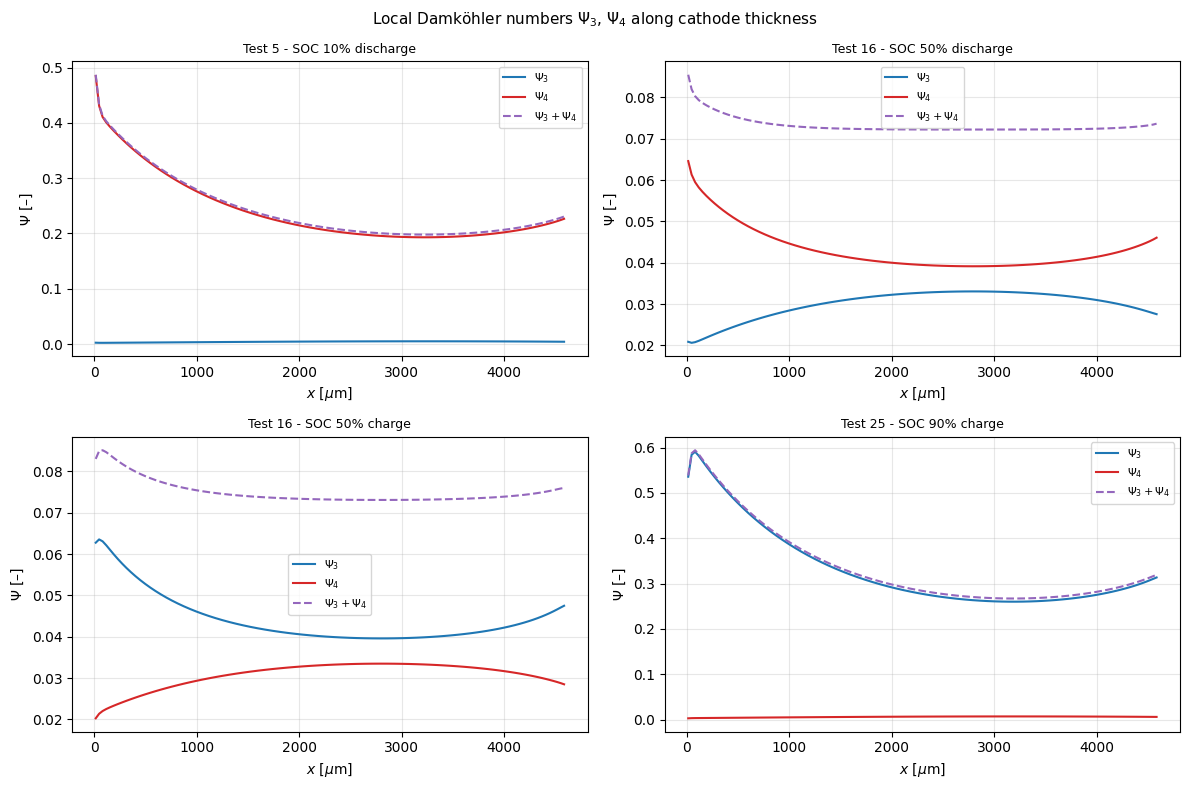

In [6]:
from rfbmodel1D.electrochem.butler_volmer import cathode_surface_concentrations

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=False)
axes = axes.flatten()

print(f"{'Case':28s}  {'Ψ₃ mean':>10s}  {'Ψ₄ mean':>10s}  {'Ψ₃+Ψ₄ mean':>12s}")
print("-" * 68)

for ax, ((test_no, mode), r) in zip(axes, cases_data.items()):
    cell_r = results[test_no, mode]["cell"]
    c_V4   = r["c_V4"]
    c_V5   = r["c_V5"]
    eta    = cell_r.cathode.eta
    x_um   = r["x_um"]
    dx_ca  = r["dx_ca"]

    _, _, _, _, Psi3, Psi4, _ = cathode_surface_concentrations(cell_r, eta, c_V4, c_V5)

    cases_data[test_no, mode]["Psi3"] = Psi3
    cases_data[test_no, mode]["Psi4"] = Psi4

    Psi3_mean = np.sum(Psi3 * dx_ca) / np.sum(dx_ca)
    Psi4_mean = np.sum(Psi4 * dx_ca) / np.sum(dx_ca)

    print(f"{r['label']:28s}  {Psi3_mean:>10.4e}  {Psi4_mean:>10.4e}  {Psi3_mean+Psi4_mean:>12.4e}")

    ax.plot(x_um, Psi3,        label=r"$\Psi_3$",          color="tab:blue")
    ax.plot(x_um, Psi4,        label=r"$\Psi_4$",          color="tab:red")
    ax.plot(x_um, Psi3 + Psi4, label=r"$\Psi_3 + \Psi_4$", color="tab:purple", linestyle="--")
    ax.set_title(r["label"], fontsize=9)
    ax.set_xlabel(r"$x$ [$\mu$m]")
    ax.set_ylabel(r"$\Psi$ [–]")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle(r"Local Damköhler numbers $\Psi_3$, $\Psi_4$ along cathode thickness", fontsize=11)
fig.tight_layout()
plt.show()

## Summary — all dimensionless numbers

## Effective ohmic resistance

Integrate the series electronic + ionic resistance $(1/\sigma + 1/\kappa_{io})$
along the cathode thickness:

$$R_{ohmic} = \int_0^{L} \left(\frac{1}{\sigma} + \frac{1}{\kappa_{io}(x)}\right) dx$$

$\sigma$ (the effective electronic conductivity) is uniform, $\kappa_{io}(x)$ varies
with the local electrolyte composition, so the integral is evaluated as a sum over
the cathode mesh nodes.

In [8]:
sigma_eff = cell.cathode.conductivity * (1 - cell.cathode.porosity)**1.5  # S/m, effective electronic conductivity

print("Effective ohmic resistance integrated over cathode thickness:")
for (test_no, mode), r in cases_data.items():
    kappa   = r["kappa_io"]   # local ionic conductivity, S/m
    dx_ca   = r["dx_ca"]      # node widths, m

    R_ohmic        = np.sum(dx_ca * (1 / kappa + 1 / sigma_eff))  # Ohm.m2
    R_ohmic_ohm_cm2 = R_ohmic * 1e4                                # Ohm.cm2

    cases_data[test_no, mode]["R_ohmic"] = R_ohmic

    print(f"{r['label']:28s} R_ohmic = {R_ohmic:.4e} Ohm.m2  = {R_ohmic_ohm_cm2:.4f} Ohm.cm2")

Effective ohmic resistance integrated over cathode thickness:
Test 5 - SOC 10% discharge   R_ohmic = 9.6374e-05 Ohm.m2  = 0.9637 Ohm.cm2
Test 16 - SOC 50% discharge  R_ohmic = 9.6932e-05 Ohm.m2  = 0.9693 Ohm.cm2
Test 16 - SOC 50% charge     R_ohmic = 9.6787e-05 Ohm.m2  = 0.9679 Ohm.cm2
Test 25 - SOC 90% charge     R_ohmic = 9.7364e-05 Ohm.m2  = 0.9736 Ohm.cm2


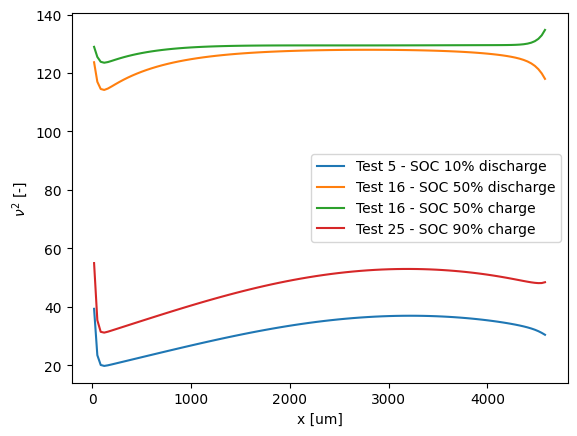

In [9]:
for (test_no, mode), r in cases_data.items():
    L     = cell.cathode.thickness
    sigma_eff = cell.cathode.conductivity * (1-cell.cathode.porosity)**1.5  # S/m, effective electronic conductivity
    a     = cell.cathode.specific_surface_area                   # m2/m3
    kappa = r["kappa_io"]
    i_0   = r["j_0_ca"]
    RT    = cell.R * cell.T  # J/mol
    F     = cell.F
    nu_square = L * (1/kappa + 1/sigma_eff) / (RT /(F*L*a*i_0))  # dimensionless, squared
    cases_data[test_no, mode]["nu_square"] = nu_square
    plt.plot(r["x_um"], nu_square, label=r["label"])
    plt.xlabel("x [um]")
    plt.ylabel(r"$\nu^2$ [-]")
    plt.legend()

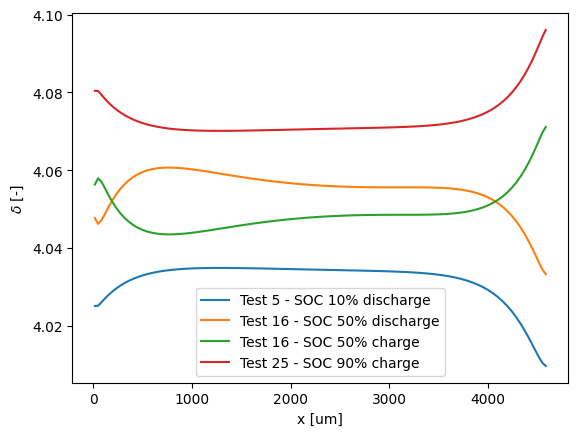

In [11]:
for (test_no, mode), r in cases_data.items():
    L     = cell.cathode.thickness
    sigma_eff = cell.cathode.conductivity * (1-cell.cathode.porosity)**1.5  # S/m, effective electronic conductivity
    a     = cell.cathode.specific_surface_area                   # m2/m3
    alpha_c = cell.alpha_c
    kappa = r["kappa_io"]
    i_0   = r["j_0_ca"]
    RT    = cell.R * cell.T  # J/mol
    F     = cell.F
    delta = L * (1/kappa + 1/sigma_eff) / (RT /(alpha_c *F* I_APPL_ABS))
    cases_data[test_no, mode]["delta"] = delta
    plt.plot(r["x_um"], delta, label=r["label"])
    plt.xlabel("x [um]")
    plt.ylabel(r"$\delta$ [-]")
    plt.legend()

## Reaction rate vs. in-plane convective supply rate (Damköhler Da₁)

Two characteristic volumetric molar rates are compared [mol m⁻³ s⁻¹]:

$$R_{\text{reac},0} = \frac{j_0}{n F L}$$

volumetric reaction rate based on the local **exchange current density** $j_0$ [A m⁻²],
distributed over the cathode thickness $L$.

$$R_{\text{reac,appl}} = \frac{i_\text{appl}}{n F L}$$

volumetric reaction rate based on the **applied current density** $i_\text{appl}$ [A m⁻²],
distributed over the cathode thickness $L$.

Both use the current density per geometric electrode area divided by $L$ — specific
surface area $a$ does not enter Da₁.

$$R_{\text{conv}} = \frac{v_\text{ip} \, c_v}{H}$$

volumetric molar supply rate by **in-plane convection**, where
$c_v = 1000 \cdot \text{SOC}$ (discharge) or $1000 \cdot (1-\text{SOC})$ (charge) [mol m⁻³],
$v_\text{ip}$ is the superficial in-plane velocity [m s⁻¹], and $H$ is the cathode height [m].

$$\text{Da}_1 = \frac{R_\text{reac}}{R_\text{conv}}$$

In [13]:
n = 1  # electrons transferred per vanadium redox event

print(f"{'Case':28s}  {'R_reac_0_mean [mol/m3/s]':>24s}  {'R_reac_appl [mol/m3/s]':>23s}  {'R_conv [mol/m3/s]':>18s}  {'Da1_0':>8s}  {'Da1_appl':>10s}")
print("-" * 110)

for (test_no, mode), r in cases_data.items():
    cell_r = results[test_no, mode]["cell"]
    i_appl = np.abs(r["i_appl"])   # A/m2 geometric electrode area
    soc    = r["soc"]

    L    = cell_r.cathode.thickness   # m
    F    = cell_r.F
    H    = cell_r.cathode.height      # m
    v_ip = cell_r.cathode.u_ip        # m/s, superficial in-plane

    j_0 = r["j_0_ca"]   # local exchange current density [A/m2]
    dx  = r["dx_ca"]

    # Bulk vanadium concentration feeding the reaction [mol/m3]
    c_v = 1000.0 * soc if mode == "discharge" else 1000.0 * (1.0 - soc)

    # Volumetric molar rates [mol/m3/s] — no specific surface area a in Da1
    # i [A/m2_geometric] / (n*F [C/mol] * L [m]) = mol/(m3*s)
    R_reac_0    = j_0 / (n * F * L)       # local profile, using exchange current density
    R_reac_appl = i_appl / (n * F * L)    # scalar, using applied current density
    R_conv      = v_ip * c_v / H          # scalar

    R_reac_0_mean = np.sum(R_reac_0 * dx) / np.sum(dx)  # thickness-weighted mean

    print(f"{r['label']:28s}  {R_reac_0_mean:>24.4e}  {R_reac_appl:>23.4e}  {R_conv:>18.4e}  {R_reac_0_mean/R_conv:>8.4e}  {R_reac_appl/R_conv:>10.4e}")

    # store for plotting
    cases_data[test_no, mode]["R_reac_0"]    = R_reac_0
    cases_data[test_no, mode]["R_reac_appl"] = R_reac_appl
    cases_data[test_no, mode]["R_conv"]      = R_conv
    cases_data[test_no, mode]["c_v"]         = c_v

Case                          R_reac_0_mean [mol/m3/s]   R_reac_appl [mol/m3/s]   R_conv [mol/m3/s]     Da1_0    Da1_appl
--------------------------------------------------------------------------------------------------------------
Test 5 - SOC 10% discharge                  2.9475e-02               4.5062e+00          5.5703e+00  5.2915e-03  8.0897e-01
Test 16 - SOC 50% discharge                 1.1566e-01               4.5062e+00          2.7852e+01  4.1529e-03  1.6179e-01
Test 16 - SOC 50% charge                    1.1915e-01               4.5062e+00          2.7852e+01  4.2779e-03  1.6179e-01
Test 25 - SOC 90% charge                    4.2850e-02               4.5062e+00          5.5703e+00  7.6925e-03  8.0897e-01


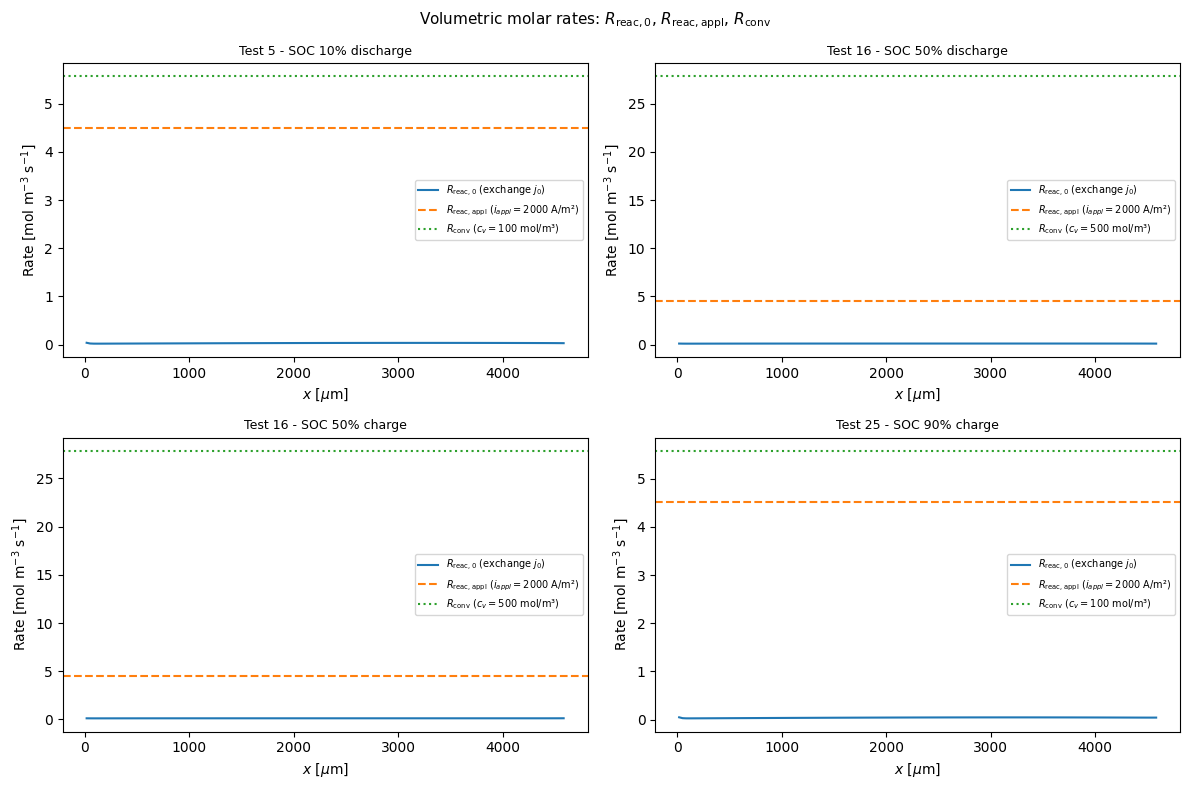

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=False)
axes = axes.flatten()

for ax, ((test_no, mode), r) in zip(axes, cases_data.items()):
    x_um        = r["x_um"]
    R_reac_0    = r["R_reac_0"]
    R_reac_appl = r["R_reac_appl"]
    R_conv      = r["R_conv"]
    i_appl      = np.abs(r["i_appl"])

    ax.plot(x_um, R_reac_0, label=r"$R_{\mathrm{reac},0}$ (exchange $j_0$)", color="tab:blue")
    ax.axhline(R_reac_appl, linestyle="--", color="tab:orange",
               label=rf"$R_{{\mathrm{{reac,appl}}}}$ ($i_{{appl}}={i_appl:.0f}$ A/m²)")
    ax.axhline(R_conv, linestyle=":", color="tab:green",
               label=rf"$R_{{\mathrm{{conv}}}}$ ($c_v={r['c_v']:.0f}$ mol/m³)")

    ax.set_title(r["label"], fontsize=9)
    ax.set_xlabel(r"$x$ [$\mu$m]")
    ax.set_ylabel(r"Rate [mol m$^{-3}$ s$^{-1}$]")
    ax.legend(fontsize=7)

fig.suptitle(r"Volumetric molar rates: $R_{\mathrm{reac},0}$, $R_{\mathrm{reac,appl}}$, $R_{\mathrm{conv}}$",
             fontsize=11)
fig.tight_layout()
plt.show()

In [18]:
header = (f"{'Case':28s}  {'ν^2 (mean)':>10s}  {'δ (mean)':>10s}  "
          f"{'Da₁':>10s}  {'Da_II':>10s}  {'Ψ₃ (mean)':>12s}  {'Ψ₄ (mean)':>12s}  {'Ψ₃+Ψ₄':>10s}")
print(header)
print("-" * len(header))

for (test_no, mode), r in cases_data.items():
    dx = r["dx_ca"]

    nu_square_mean = np.sum(r["nu_square"] * dx) / np.sum(dx)
    delta_mean = np.sum(r["delta"]     * dx) / np.sum(dx)
    Da1        = r["R_reac_appl"] / r["R_conv"]
    Da2        = r["Da_II"]
    Psi3_mean  = np.sum(r["Psi3"] * dx) / np.sum(dx)
    Psi4_mean  = np.sum(r["Psi4"] * dx) / np.sum(dx)

    print(f"{r['label']:28s}  {nu_square_mean:>10.4e}  {delta_mean:>10.4e}  "
          f"{Da1:>10.4e}  {Da2:>10.4e}  {Psi3_mean:>12.4e}  {Psi4_mean:>12.4e}  {Psi3_mean+Psi4_mean:>10.4e}")

Case                          ν^2 (mean)    δ (mean)         Da₁       Da_II     Ψ₃ (mean)     Ψ₄ (mean)       Ψ₃+Ψ₄
--------------------------------------------------------------------------------------------------------------------
Test 5 - SOC 10% discharge    3.1761e+01  4.0317e+00  8.0897e-01  1.0034e-02    4.0481e-03    2.4092e-01  2.4497e-01
Test 16 - SOC 50% discharge   1.2536e+02  4.0551e+00  1.6179e-01  2.0069e-03    3.0033e-02    4.3197e-02  7.3230e-02
Test 16 - SOC 50% charge      1.2894e+02  4.0490e+00  1.6179e-01  2.0069e-03    4.4264e-02    3.0728e-02  7.4992e-02
Test 25 - SOC 90% charge      4.6647e+01  4.0731e+00  8.0897e-01  1.0034e-02    3.3195e-01    5.9315e-03  3.3788e-01


## Save cases to disk

In [16]:
# Flatten the per-case dict into a single npz (np.savez doesn't support nested
# dicts), keyed as "{test_no}_{mode}_{field}" so later cells can reload without
# re-running the DAE solve.
save_path = ROOT / "results" / "adim_analysis_cases.npz"
save_path.parent.mkdir(parents=True, exist_ok=True)

flat = {"case_keys": np.array([f"{t}_{m}" for (t, m) in cases_data], dtype=object)}
for (test_no, mode), d in cases_data.items():
    prefix = f"{test_no}_{mode}_"
    for field, value in d.items():
        flat[prefix + field] = np.asarray(value) if not isinstance(value, str) else value

#np.savez(save_path, **flat)
#print(f"Saved {len(cases_data)} case(s) to {save_path}")